In [14]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import cv2
import numpy as np
from torch.utils.data import DataLoader
from datasets import load_dataset
from torch.amp import autocast, GradScaler
from tqdm import tqdm
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.version.cuda)
print(f"running on {device}")

13.4
running on cuda


In [15]:
class SeparableConv(nn.Module):
    def __init__(self, c_in, c_out, kernel_size = 3, stride = 1, padding = None):
        super().__init__()

        if padding is None: padding = kernel_size//2
        self.dw = nn.Conv2d(c_in, c_in, kernel_size=kernel_size, stride=stride, padding=padding, groups=c_in, bias=False)
        self.dbn = nn.BatchNorm2d(c_in)
        self.pw = nn.Conv2d(c_in, c_out, kernel_size=1, padding=0, stride=1, bias=False)
        self.pbn = nn.BatchNorm2d(c_out)

    def forward(self, x):
        h = F.relu(self.dbn(self.dw(x)))
        return F.relu(self.pbn(self.pw(h)))

class EncoderLayer(nn.Module):
    def __init__(self, c_in, c_out, p_dropout=0.05, scale = 2):
        super().__init__()
        self.c1 = SeparableConv(c_in, c_out)
        self.c2 = SeparableConv(c_out, c_out)
        self.c3 = SeparableConv(c_out, c_out)

        self.dropout = nn.Dropout(p = p_dropout)
        self.pool = nn.MaxPool2d(scale, scale)

    def forward(self, x):
        h = self.c1(x)
        h = self.c2(h)
        h = self.dropout(self.c3(h))
        return self.pool(h), h

class DecoderLayer(nn.Module):
    def __init__(self, c_in, c_skip, c_out, p_dropout=0.1, scale = 2):
        super().__init__()
        self.c1 = SeparableConv(c_in + c_skip, c_in)
        self.c2 = SeparableConv(c_in, c_in)
        self.c3 = SeparableConv(c_in, c_out)

        self.upsample = nn.Sequential(
            nn.Conv2d(c_in, c_in*(scale**2), kernel_size=1, stride=1, padding=0),
            nn.PixelShuffle(scale)
        )

        self.dropout = nn.Dropout(p = p_dropout)

    def forward(self, x_skip, x_low):
        upsampled = self.upsample(x_low)
        h = self.c1(torch.cat([x_skip, upsampled], dim=1))
        h = self.c2(h)
        h = self.c3(h)

        return self.dropout(h)

class UNet(nn.Module):
    def __init__(self, output_classes=19, layer_count=3, raw_channels = 3, scale=2, channel_outs=None):
        super().__init__()
        self.layer_count = layer_count
        self.scale = scale

        if channel_outs is None:
            channel_outs = [64, 96, 128, 128, 96, 64]

        self.first = nn.Sequential( 
            nn.Conv2d(in_channels=raw_channels, out_channels=channel_outs[0], kernel_size=7, padding=3, stride=1),
            SeparableConv(channel_outs[0], channel_outs[0])
        )

        self.down = nn.MaxPool2d(self.scale, self.scale)

        self.encoders = nn.ModuleList([
            EncoderLayer(channel_outs[i], channel_outs[i+1], scale=self.scale) for i in range(layer_count-1)# 1->2, 2->3
        ])

        self.bottom_layer = nn.Sequential( # 3->3
            SeparableConv(channel_outs[layer_count-1], channel_outs[layer_count-1], kernel_size=3, padding=1, stride=1),
            SeparableConv(channel_outs[layer_count-1], channel_outs[layer_count], kernel_size=3, padding=1, stride=1),
        )

        self.decoders = nn.ModuleList([
            DecoderLayer(channel_outs[i], channel_outs[-i - 1], channel_outs[i+1], scale=self.scale) # 3->2 (no resid), 2->1 (resid from encoders[0])
            for i in range(layer_count, len(channel_outs)-1)
        ])

        self.upscaler = nn.Sequential(
            nn.Conv2d(channel_outs[-1], channel_outs[-1]*(self.scale**2), kernel_size=1, stride=1, padding=0),
            nn.PixelShuffle(self.scale)
        )

        self.out = nn.Sequential( 
            SeparableConv(channel_outs[-1] + channel_outs[0], channel_outs[-1]),
            nn.Conv2d(channel_outs[-1], output_classes, kernel_size=3, padding=1, stride=1)
        )

    def forward(self, x):

        first_act = self.first(x)
        activations = [first_act]
        h = self.down(first_act)
        for encoder in self.encoders:
            h, a_map = encoder(h)
            activations.append(a_map)

        up = self.bottom_layer(h)

        for i, decoder in enumerate(self.decoders):
            up = decoder(activations[-i - 1], up)

        up = self.upscaler(up)

        return self.out(torch.cat([activations[0], up], dim = 1))

In [ ]:
train_ds = load_dataset(
    "tanganke/cityscapes",
    split="train",
    # streaming=True
)

val_ds = load_dataset(
    "tanganke/cityscapes",
    split="validation",
    # streaming=True
)

def prepare_example(example):
    image = torch.tensor(
        np.array(example["image"]),
        dtype=torch.float32
    ) 

    mask = torch.tensor(
        np.array(example["segmentation_19"]),
        dtype=torch.long
    )

    # mask[mask == -1] = 19
    

    return {
        "image": image,
        "mask": mask,
    }

train_ds = train_ds.with_transform(prepare_example)
val_ds = val_ds.with_transform(prepare_example)

train_loader = DataLoader(
    train_ds,
    batch_size=64,
    num_workers=4,       # Increased from 2
    pin_memory=True,     # Added for faster GPU transfer
    shuffle=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=64,
    num_workers=4,
    pin_memory=True,
    shuffle=False
)

In [ ]:
scaler = GradScaler('cuda')

# Re-initialize model, criterion, and optimizer after changing the architecture
model = UNet(output_classes=19, layer_count=5, channel_outs=[64, 96, 128, 192, 256, 256, 192, 128, 96, 64]).to(device)
criterion = torch.nn.CrossEntropyLoss(ignore_index=-1)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)

print(model)
total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params:,}")

UNet(
  (first): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
    (1): SeparableConv(
      (dw): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64, bias=False)
      (dbn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (pw): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (pbn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
  )
  (down): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (encoders): ModuleList(
    (0): EncoderLayer(
      (c1): SeparableConv(
        (dw): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64, bias=False)
        (dbn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (pw): Conv2d(64, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (pbn): BatchNorm2d(96, eps

In [18]:
for epoch in range(50):
    model.train()
    running_loss = 0.0
    batches = 0

    for batch in tqdm(train_loader):
        images = batch["image"].to(device, non_blocking=True)
        masks = batch["mask"].to(device, non_blocking=True)

        optimizer.zero_grad()

        # 1. Forward pass in mixed precision (FP16)
        with autocast('cuda'):
            logits = model(images)
            
        # 2. Compute loss in FP32 (Crucial: prevents log_softmax overflow)
        loss = criterion(logits.float(), masks)

        # 3. Backward pass and optimization
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        
        # Gradient clipping is good, keep it
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
        batches += 1

    print(f"Epoch {epoch + 1}: loss = {running_loss / batches:.4f}")

100%|██████████| 186/186 [00:24<00:00,  7.55it/s]


Epoch 1: loss = 1.2582


100%|██████████| 186/186 [00:20<00:00,  8.95it/s]


Epoch 2: loss = 0.8335


100%|██████████| 186/186 [00:20<00:00,  8.89it/s]


Epoch 3: loss = 0.7618


... (90 outputs left out)

100%|██████████| 186/186 [00:22<00:00,  8.45it/s]


Epoch 49: loss = 0.2368


100%|██████████| 186/186 [00:21<00:00,  8.46it/s]

Epoch 50: loss = 0.2344


In [21]:
torch.save(model.state_dict(), 'checkpoints/model_weights_1.pt')


# model = UNet(output_classes=19, layer_count=3) 
# model.load_state_dict(torch.load('checkpoints/model_weights_1.pt', weights_only=True))
# model =model.to(device)

{'image': tensor([[[[0.4314, 0.4510, 0.4549,  ..., 0.5216, 0.5412, 0.5529],
          [0.3882, 0.4392, 0.4549,  ..., 0.5098, 0.5216, 0.5216],
          [0.4078, 0.4431, 0.4588,  ..., 0.4980, 0.4980, 0.4902],
          ...,
          [0.3412, 0.3490, 0.3373,  ..., 0.1098, 0.1216, 0.1647],
          [0.3412, 0.3490, 0.3373,  ..., 0.1216, 0.1373, 0.2588],
          [0.3412, 0.3490, 0.3373,  ..., 0.1333, 0.1255, 0.2510]],

         [[0.4745, 0.4863, 0.4902,  ..., 0.5725, 0.6078, 0.6000],
          [0.4353, 0.4745, 0.4863,  ..., 0.5569, 0.5765, 0.5647],
          [0.4471, 0.4784, 0.4863,  ..., 0.5373, 0.5412, 0.5216],
          ...,
          [0.4078, 0.4118, 0.4000,  ..., 0.1373, 0.1569, 0.2078],
          [0.4078, 0.4118, 0.4000,  ..., 0.1412, 0.1647, 0.3098],
          [0.4078, 0.4118, 0.4000,  ..., 0.1451, 0.1490, 0.3020]],

         [[0.3255, 0.3647, 0.3882,  ..., 0.4235, 0.4784, 0.4941],
          [0.2627, 0.3490, 0.3843,  ..., 0.4000, 0.4392, 0.4510],
          [0.2706, 0.3529, 0.384

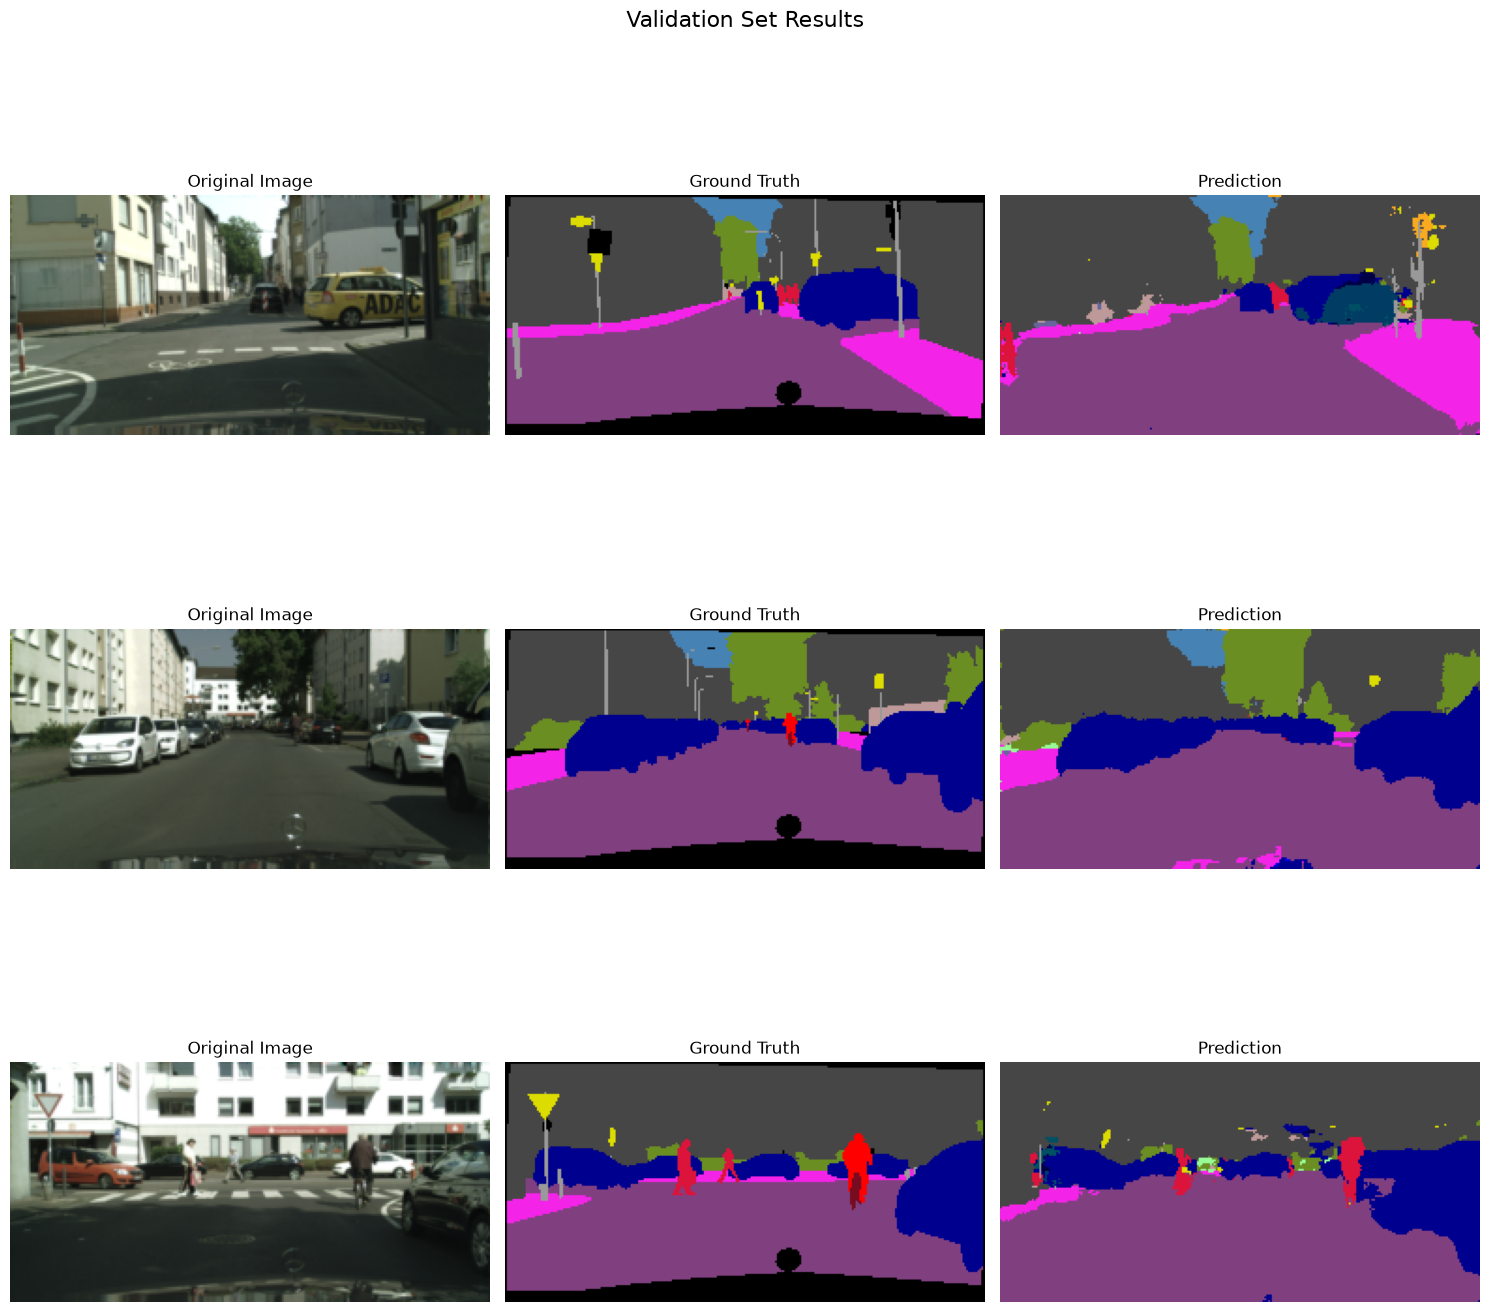

UNet(
  (first): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
    (1): SeparableConv(
      (dw): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64, bias=False)
      (dbn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (pw): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (pbn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
  )
  (down): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (encoders): ModuleList(
    (0): EncoderLayer(
      (c1): SeparableConv(
        (dw): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64, bias=False)
        (dbn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (pw): Conv2d(64, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (pbn): BatchNorm2d(96, eps

In [22]:
# 1. Define the official Cityscapes 19-class color palette (RGB)
CITYSCAPES_COLORS = np.array([
    [128, 64, 128],  # 0: road
    [244, 35, 232],  # 1: sidewalk
    [70, 70, 70],    # 2: building
    [102, 102, 156], # 3: wall
    [190, 153, 153], # 4: fence
    [153, 153, 153], # 5: pole
    [250, 170, 30],  # 6: traffic light
    [220, 220, 0],   # 7: traffic sign
    [107, 142, 35],  # 8: vegetation
    [152, 251, 152], # 9: terrain
    [70, 130, 180],  # 10: sky
    [220, 20, 60],   # 11: person
    [255, 0, 0],     # 12: rider
    [0, 0, 142],     # 13: car
    [0, 0, 70],      # 14: truck
    [0, 60, 100],    # 15: bus
    [0, 80, 100],    # 16: train
    [0, 0, 230],     # 17: motorcycle
    [119, 11, 32],    # 18: bicycle,
    [0,0,0]
], dtype=np.uint8)

def colorize_mask(mask_tensor):
    """Converts a 2D tensor of class indices into an RGB image."""
    mask_np = mask_tensor.cpu().numpy()
    h, w = mask_np.shape
    color_mask = np.zeros((h, w, 3), dtype=np.uint8) # Defaults to black for ignore_index (-1)
    
    for i in range(19):
        color_mask[mask_np == i] = CITYSCAPES_COLORS[i]
        
    return color_mask

# 2. Set model to evaluation mode and disable gradient calculation
model.eval()
with torch.no_grad():
    # Grab a single batch from the validation loader
    batch = next(iter(val_loader))
    print(batch)
    images = batch["image"].to(device)
    masks = batch["mask"]
    
    # Get predictions
    logits = model(images)
    # Argmax over the class dimension (dim=1) to get the predicted class indices
    preds = torch.argmax(logits, dim=1) 

# 3. Plot the results (Showing 3 examples from the batch)
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
fig.suptitle("Validation Set Results", fontsize=16)

for i in range(3):
    # --- Original Image ---
    img = images[i].cpu().numpy()
    # Ensure image is in (H, W, C) format for matplotlib
    if img.shape[0] == 3: 
        img = np.transpose(img, (1, 2, 0))
    # Normalize to 0-1 for display (since you didn't normalize in prepare_example)
    img = (img - img.min()) / (img.max() - img.min() + 1e-8) 
    
    axes[i, 0].imshow(img)
    axes[i, 0].set_title("Original Image")
    axes[i, 0].axis('off')
    
    # --- Ground Truth Mask ---
    gt_color = colorize_mask(masks[i])
    axes[i, 1].imshow(gt_color)
    axes[i, 1].set_title("Ground Truth")
    axes[i, 1].axis('off')
    
    # --- Predicted Mask ---
    pred_color = colorize_mask(preds[i])
    axes[i, 2].imshow(pred_color)
    axes[i, 2].set_title("Prediction")
    axes[i, 2].axis('off')

plt.tight_layout()
plt.show()

# Don't forget to set back to train mode if you are continuing training in the next cell!
model.train()